# 03 · SQL Analysis, KPI Scorecard & Statistical Testing
**Duka Electronics · H1 2026 · Phase 4 (Analyse)**

**Project brief**
* **Stakeholder:** Commercial Director, Duka Electronics.
* **Decision:** where to focus H2 2026 marketing spend and management attention.
* **Questions:** Q1 Which branches are growing/shrinking? Q2 Which products/categories drive revenue? Q3 Is the Q2 change real or noise?
  Q4 Are returns/cancellations behind it? Q5 What do customers and payments look like?
* **Success criteria:** every question answered with a number, one statistical test with an effect size, and at least three quantified recommendations.

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
DB = ROOT / "data" / "duka.db"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid.axis": "y"})
BRANCH_COLORS = {"Nairobi": "#1F4E79", "Mombasa": "#C0504D", "Nakuru": "#E39B3B",
                 "Eldoret": "#2E8B57", "Kisumu": "#8C8C8C"}
pd.options.display.float_format = "{:,.1f}".format

def save_fig(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=150)

import re
from scipy import stats
con = sqlite3.connect(DB)

## 1. SQL analysis
Queries live in `sql/queries.sql` (single source of truth). Each block starts with `-- Qn:`; they are loaded and run with `pd.read_sql`.

In [2]:
text = (ROOT / "sql" / "queries.sql").read_text()
blocks = re.split(r"(?m)^-- (Q\d+): ", text)[1:]
queries = {blocks[i]: blocks[i + 1] for i in range(0, len(blocks), 2)}
results = {}
for qid, body in queries.items():
    title, sql = body.split("\n", 1)              # first line = question, rest = SQL
    results[qid] = pd.read_sql(sql, con)
    print(f"{qid}: {title}  -> {len(results[qid])} rows")

Q1: Which branches are growing or shrinking? Quarter-on-quarter revenue by branch.  -> 10 rows
Q2: Which product categories drive revenue versus order volume?  -> 6 rows
Q3: Which individual products are proven, high-volume revenue earners?  -> 8 rows
Q4: What is each branch's month-on-month trend?  -> 30 rows
Q5: What are the top two products by revenue inside each category?  -> 12 rows
Q6: Do returns or cancellations differ by branch (a possible cause of the Q2 drop)?  -> 5 rows
Q7: Who are the customers? Revenue by age band for identified customers.  -> 6 rows
Q8: How do customers pay, by sales channel?  -> 10 rows


### Q1 · Quarter-on-quarter growth by branch (window function `LAG`)

In [3]:
q1 = results["Q1"]; q1[q1["quarter"] == "Q2"][["branch", "prev_quarter_revenue", "revenue", "qoq_growth_pct"]].sort_values("qoq_growth_pct")

,branch,prev_quarter_revenue,revenue,qoq_growth_pct
9,Nakuru,"32,380,567.0","22,885,513.0",-29.3
5,Mombasa,"38,099,873.0","27,781,336.0",-27.1
7,Nairobi,"65,425,883.0","67,190,803.0",2.7
3,Kisumu,"22,785,238.0","25,137,332.0",10.3
1,Eldoret,"17,937,846.0","31,297,879.0",74.5


### Q2 · Category share of orders vs revenue (`JOIN` + window total)

In [4]:
results["Q2"]

,category,order_lines,revenue,pct_of_orders,pct_of_revenue
0,Smartphones,2120,"169,002,936.0",15.0,48.2
1,Laptops,989,"88,104,130.0",7.0,25.1
2,TVs,651,"27,240,806.0",4.6,7.8
3,Audio,2192,"23,776,869.0",15.5,6.8
4,Accessories,6252,"23,303,843.0",44.2,6.6
5,Appliances,1939,"19,493,686.0",13.7,5.6


### Q3 · Proven revenue earners (`GROUP BY … HAVING`)

In [5]:
results["Q3"]

,product_name,category,order_lines,revenue,avg_discount_pct
0,iPhone-style 15 Phone,Smartphones,508,"80,810,175.0",3.2
1,Galaxy-style S24 Phone,Smartphones,582,"64,585,004.0",2.7
2,UltraSlim 13 Laptop,Laptops,250,"32,899,824.0",3.3
3,ProBook 15 Laptop,Laptops,246,"23,672,121.0",3.2
4,ProBook 14 Laptop,Laptops,230,"18,654,863.0",3.7
5,Galaxy-style A15 Phone,Smartphones,509,"14,497,011.0",3.0
6,Smart TV 55in,TVs,217,"13,910,000.0",3.3
7,StudyMate Laptop,Laptops,263,"12,877,323.0",3.1


### Q4 · Month-on-month trend by branch (`LAG` partitioned by branch)

In [6]:
results["Q4"].pivot(index="month", columns="branch", values="mom_growth_pct")

branch,Eldoret,Kisumu,Mombasa,Nairobi,Nakuru
month,,,,,
2026-01,NaN,NaN,NaN,NaN,NaN
2026-02,5.1,-23.4,1.8,-5.9,20.1
2026-03,-8.1,28.3,3.6,11.5,-13.4
2026-04,50.5,-8.0,-29.0,-13.4,-30.9
2026-05,33.6,26.9,11.8,24.0,11.9
2026-06,-3.8,-14.2,-21.7,-8.1,-4.3


### Q5 · Top two products per category (`RANK() OVER`)

In [7]:
results["Q5"]

,category,rank_in_category,product_name,revenue
0,Accessories,1,Power Bank 20000mAh,"7,969,396.0"
1,Accessories,2,Laptop Bag,"6,812,378.0"
2,Appliances,1,Microwave 25L,"8,538,534.0"
3,Appliances,2,Air Fryer 5L,"6,074,056.0"
4,Audio,1,Soundbar 2.1,"9,968,416.0"
5,Audio,2,Headphones Over-Ear,"6,243,847.0"
6,Laptops,1,UltraSlim 13 Laptop,"32,899,824.0"
7,Laptops,2,ProBook 15 Laptop,"23,672,121.0"
8,Smartphones,1,iPhone-style 15 Phone,"80,810,175.0"
9,Smartphones,2,Galaxy-style S24 Phone,"64,585,004.0"


### Q6 · Return and cancellation rates by branch

In [8]:
results["Q6"]

,branch,order_lines,return_rate_pct,cancel_rate_pct
0,Nakuru,2457,5.7,3.4
1,Mombasa,2878,5.3,2.9
2,Eldoret,2137,5.2,2.6
3,Kisumu,2092,4.9,3.7
4,Nairobi,5803,4.3,2.9


### Q7 · Revenue by customer age band (pseudonymised `JOIN`)

In [9]:
results["Q7"]

,age_band,customers,revenue,revenue_per_customer
0,25-34,935,"105,394,245.0","112,721.0"
1,35-44,865,"101,535,807.0","117,382.0"
2,18-24,523,"60,328,272.0","115,350.0"
3,45-54,385,"44,697,362.0","116,097.0"
4,Unknown,161,"19,488,240.0","121,045.0"
5,55+,99,"12,227,797.0","123,513.0"


### Q8 · Payment method by channel

In [10]:
results["Q8"]

,channel,payment_method,order_lines,pct_within_channel
0,In-store,M-Pesa,4624,45.7
1,In-store,Cash,3680,36.3
2,In-store,Card,1267,12.5
3,In-store,Bank Transfer,284,2.8
4,In-store,Unknown,271,2.7
5,Online,M-Pesa,2372,60.3
6,Online,Card,1104,28.1
7,Online,Bank Transfer,293,7.5
8,Online,Unknown,128,3.3
9,Online,Cash,34,0.9


## 2. KPI scorecard
All revenue KPIs use **completed** lines. *Net revenue = quantity × unit price × (1 − discount%).*

In [11]:
df = pd.read_sql("""SELECT o.*, p.category FROM orders o JOIN products p USING(product_id)""", con, parse_dates=["order_date"])
done = df[df.is_completed == 1]
known = done[done.customer_key != "UNKNOWN"]
q = done.groupby("quarter")["net_revenue"].sum()
by_branch = done.groupby("branch")["net_revenue"].sum()
chan = done[done.channel != "Unknown"]
freq = known.groupby("customer_key").size()

kpi = pd.DataFrame([
 ("Net revenue (KES)", done.net_revenue.sum(), "Sum of net_revenue, completed lines"),
 ("Completed order lines", len(done), "Count of lines with order_status = Completed"),
 ("Average order value (KES)", done.net_revenue.mean(), "Net revenue / completed lines"),
 ("Median order value (KES)", done.net_revenue.median(), "Median net_revenue per completed line (robust to skew)"),
 ("Units sold", done.quantity.sum(), "Sum of quantity, completed lines"),
 ("Discount rate (%)", 100 * done.discount_kes.sum() / done.gross_revenue.sum(), "Discount KES / gross revenue"),
 ("Return rate (%)", 100 * (df.order_status == "Returned").mean(), "Returned lines / all lines"),
 ("Cancellation rate (%)", 100 * (df.order_status == "Cancelled").mean(), "Cancelled lines / all lines"),
 ("Q2 vs Q1 revenue growth (%)", 100 * (q["Q2"] / q["Q1"] - 1), "(Q2 net revenue / Q1 net revenue) - 1"),
 ("Largest branch share of revenue (%)", 100 * by_branch.max() / by_branch.sum(), f"{by_branch.idxmax()} revenue / total revenue"),
 ("Smartphone + laptop share of revenue (%)", 100 * done[done.category.isin(["Smartphones", "Laptops"])].net_revenue.sum() / done.net_revenue.sum(), "Revenue share of the two categories"),
 ("Online share of revenue (%)", 100 * chan[chan.channel == "Online"].net_revenue.sum() / chan.net_revenue.sum(), "Online revenue / revenue with known channel"),
 ("Repeat-customer rate (%)", 100 * (freq >= 2).mean(), "Identified customers with 2+ completed lines / identified customers"),
], columns=["KPI", "Value", "Definition"])
kpi["Value"] = kpi["Value"].astype(float)
kpi.to_csv(TAB / "kpi_scorecard.csv", index=False)
kpi.style.format({"Value": "{:,.1f}"}).hide(axis="index")

KPI,Value,Definition
Net revenue (KES),"350,922,270.7","Sum of net_revenue, completed lines"
Completed order lines,"14,143.0",Count of lines with order_status = Completed
Average order value (KES),"24,812.4",Net revenue / completed lines
Median order value (KES),"6,600.0",Median net_revenue per completed line (robust to skew)
Units sold,"20,328.0","Sum of quantity, completed lines"
Discount rate (%),3.2,Discount KES / gross revenue
Return rate (%),4.9,Returned lines / all lines
Cancellation rate (%),3.0,Cancelled lines / all lines
Q2 vs Q1 revenue growth (%),-1.3,(Q2 net revenue / Q1 net revenue) - 1
Largest branch share of revenue (%),37.8,Nairobi revenue / total revenue


> **Data caveat:** with 3,000 simulated customers and ~14k lines the repeat rate is high by construction; treat it as indicative only.

## 3. Statistical testing

### Test 1 – Did daily revenue really change between Q1 and Q2, by branch?
* **H0:** the distribution of daily branch revenue is the same in Q1 and Q2. **H1:** it differs (two-sided).
* **Test:** Mann-Whitney U, because daily revenue is skewed (see EDA). Five branches are tested, so **Bonferroni α = 0.05 / 5 = 0.01**.
* **Effect size:** rank-biserial correlation *r* (|r| ≥ 0.5 large) and a bootstrap 95% CI for the % change in mean daily revenue.

In [12]:
rng = np.random.default_rng(42)
days = pd.date_range("2026-01-01", "2026-06-30")
daily = (done.groupby(["branch", "order_date"])["net_revenue"].sum().unstack(0)
             .reindex(days).fillna(0))
q1d, q2d = daily.loc["2026-01-01":"2026-03-31"], daily.loc["2026-04-01":"2026-06-30"]

def boot_pct_change(a, b, n=5000):
    a, b = np.asarray(a), np.asarray(b)
    out = [(rng.choice(b, len(b)).mean() / rng.choice(a, len(a)).mean() - 1) * 100 for _ in range(n)]
    return np.percentile(out, [2.5, 97.5])

rows = []
for b in ["Nairobi", "Mombasa", "Nakuru", "Kisumu", "Eldoret"]:
    u, p = stats.mannwhitneyu(q1d[b], q2d[b], alternative="two-sided")
    r = 1 - 2 * u / (len(q1d) * len(q2d))        # rank-biserial (positive => Q1 higher)
    lo, hi = boot_pct_change(q1d[b], q2d[b])
    rows.append({"branch": b, "mean_daily_Q1": q1d[b].mean(), "mean_daily_Q2": q2d[b].mean(),
                 "pct_change": 100 * (q2d[b].mean() / q1d[b].mean() - 1), "CI95_low": lo, "CI95_high": hi,
                 "U": u, "p_value": p, "rank_biserial_r": -r, "significant_at_0.01": p < 0.01})
t1 = pd.DataFrame(rows).set_index("branch")
t1.to_csv(TAB / "test1_mannwhitney.csv")
t1.style.format({"mean_daily_Q1": "{:,.0f}", "mean_daily_Q2": "{:,.0f}", "pct_change": "{:+.1f}", "CI95_low": "{:+.1f}",
                 "CI95_high": "{:+.1f}", "U": "{:,.0f}", "p_value": "{:.2e}", "rank_biserial_r": "{:+.2f}"})

,mean_daily_Q1,mean_daily_Q2,pct_change,CI95_low,CI95_high,U,p_value,rank_biserial_r,significant_at_0.01
branch,,,,,,,,,
Nairobi,"726,954","738,360",+1.6,-8.1,+11.8,"4,060",9.22e-01,-0.01,False
Mombasa,"423,332","305,289",-27.9,-38.2,-16.3,"5,473",9.29e-05,+0.34,True
Nakuru,"359,784","251,489",-30.1,-40.7,-17.4,"5,396",2.24e-04,+0.32,True
Kisumu,"253,169","276,234",+9.1,-6.6,+28.4,"3,756",3.37e-01,-0.08,False
Eldoret,"199,309","343,933",+72.6,+44.9,+105.8,"2,228",1.18e-07,-0.46,True


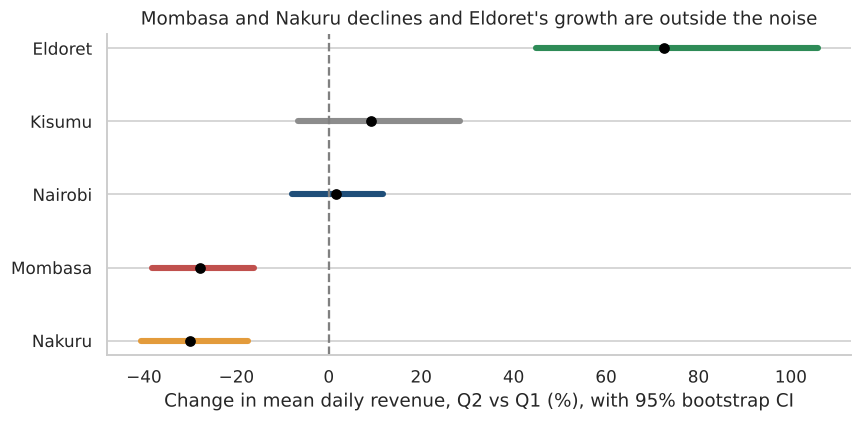

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
order = t1.sort_values("pct_change").index
for i, b in enumerate(order):
    ax.plot([t1.loc[b, "CI95_low"], t1.loc[b, "CI95_high"]], [i, i], color=BRANCH_COLORS[b], lw=4, solid_capstyle="round")
    ax.plot(t1.loc[b, "pct_change"], i, "o", color="black", ms=6)
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("Change in mean daily revenue, Q2 vs Q1 (%), with 95% bootstrap CI")
ax.set_title("Mombasa and Nakuru declines and Eldoret's growth are outside the noise")
plt.tight_layout(); save_fig(fig, "03_effect_sizes.png"); plt.show()

**Interpretation.** (Rank-biserial *r* is positive when Q1 is higher; |r| ≈ 0.3 is medium, ≥ 0.5 large.)
* **Mombasa −28%** (95% CI −38% to −16%, p < 0.001, r = +0.34) and **Nakuru −30%** (CI −41% to −17%, p < 0.001, r = +0.32) fell significantly.
* **Eldoret +73%** (CI +45% to +106%, p < 0.001, r = −0.46) grew significantly.
* **Nairobi +2%** (CI −8% to +12%) and **Kisumu +9%** (CI −7% to +28%) are *not* distinguishable from day-to-day noise (p = 0.92 and 0.34).

So the three big Q2 movements are **real shifts, not random fluctuation**, while Nairobi and Kisumu are statistically flat. The test says *that* revenue changed, not *why*; it also treats days as independent, which ignores weekday seasonality (a limitation). Daily-mean changes differ slightly from the quarterly-total growth in the KPI table because Q2 has 91 days vs 90 in Q1.

### Test 2 – Are returns/cancellations different by branch? (chi-square test of independence)
* **H0:** order status is independent of branch. **H1:** status depends on branch. α = 0.05. Effect size: Cramér's V (< 0.1 negligible).

In [14]:
ct = pd.crosstab(df["branch"], df["order_status"])
chi2, p, dof, expected = stats.chi2_contingency(ct)
n = ct.values.sum(); v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"chi2({dof}) = {chi2:.2f}, p = {p:.3f}, Cramér's V = {v:.3f}, min expected count = {expected.min():.0f}")
(100 * ct.div(ct.sum(axis=1), axis=0)).round(1)

chi2(8) = 15.72, p = 0.046, Cramér's V = 0.023, min expected count = 64


order_status,Cancelled,Completed,Returned
branch,,,
Eldoret,2.6,92.3,5.1
Kisumu,3.7,91.4,4.9
Mombasa,2.9,91.8,5.3
Nairobi,2.9,92.8,4.3
Nakuru,3.4,90.9,5.7


**Interpretation.** χ²(8) = 15.7, p = 0.046 – only *just* below 0.05 – and Cramér's V = 0.023, which is a **negligible** effect. Return rates run from 4.3% (Nairobi) to 5.7% (Nakuru): a gap of about 1.4 percentage points. Even if that gap is real, it is far too small to explain a ~30% fall in revenue at Mombasa and Nakuru, and with a large sample (n ≈ 15k) tiny differences become "significant". Statistical significance is not practical significance, so **returns do not explain the decline**. Nakuru's return rate is still worth a routine check.

## 4. Charts for the report and slides

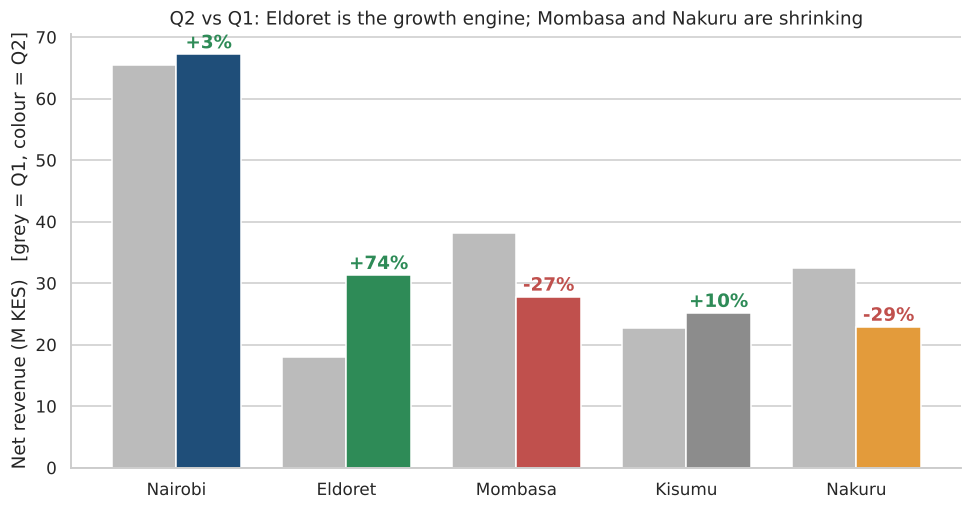

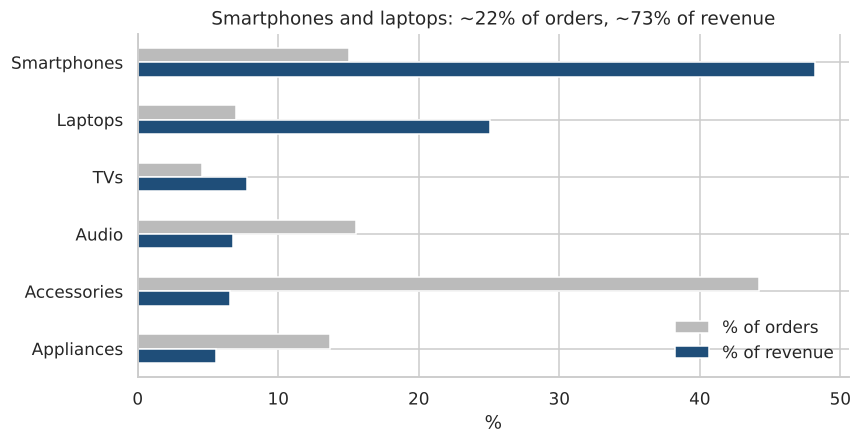

In [15]:
bq = done.pivot_table(index="branch", columns="quarter", values="net_revenue", aggfunc="sum") / 1e6
bq["growth"] = 100 * (bq["Q2"] / bq["Q1"] - 1)
bq = bq.sort_values("Q2", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(bq)); w = 0.38
ax.bar(x - w/2, bq["Q1"], w, color="#BBBBBB", label="Q1")
ax.bar(x + w/2, bq["Q2"], w, color=[BRANCH_COLORS[b] for b in bq.index], label="Q2")
for i, (b, r) in enumerate(bq.iterrows()):
    ax.text(i + w/2, r["Q2"] + 1, f"{r['growth']:+.0f}%", ha="center", fontweight="bold",
            color="#C0504D" if r["growth"] < 0 else "#2E8B57")
ax.set_xticks(x); ax.set_xticklabels(bq.index); ax.set_ylabel("Net revenue (M KES)   [grey = Q1, colour = Q2]")
ax.set_title("Q2 vs Q1: Eldoret is the growth engine; Mombasa and Nakuru are shrinking")
plt.tight_layout(); save_fig(fig, "03_branch_growth.png"); plt.show()

c2 = results["Q2"].set_index("category")
fig, ax = plt.subplots(figsize=(8, 4.2))
c2[["pct_of_orders", "pct_of_revenue"]].plot.barh(ax=ax, color=["#BBBBBB", "#1F4E79"])
ax.invert_yaxis(); ax.set_xlabel("%"); ax.set_ylabel(""); ax.legend(["% of orders", "% of revenue"], frameon=False)
ax.set_title("Smartphones and laptops: ~22% of orders, ~73% of revenue")
plt.tight_layout(); save_fig(fig, "03_category_share.png"); plt.show()

## 5. Export tables for the stakeholder workbook and dashboard

In [16]:
branch = done.groupby("branch").agg(net_revenue=("net_revenue", "sum"), order_lines=("order_id", "count"), units=("quantity", "sum"))
branch["avg_order_value"] = branch["net_revenue"] / branch["order_lines"]
bqq = done.pivot_table(index="branch", columns="quarter", values="net_revenue", aggfunc="sum")
branch["q1_revenue"], branch["q2_revenue"] = bqq["Q1"], bqq["Q2"]
branch["q2_vs_q1_growth_pct"] = 100 * (bqq["Q2"] / bqq["Q1"] - 1)
branch["share_of_revenue_pct"] = 100 * branch["net_revenue"] / branch["net_revenue"].sum()
branch["return_rate_pct"] = df.groupby("branch")["order_status"].apply(lambda s: 100 * (s == "Returned").mean())
branch.reset_index().to_csv(TAB / "branch_summary.csv", index=False)

cat = done.groupby("category").agg(net_revenue=("net_revenue", "sum"), order_lines=("order_id", "count"), units=("quantity", "sum")).reset_index()
cat.to_csv(TAB / "category_summary.csv", index=False)

mb = done.groupby(["month", "branch", "category"]).agg(net_revenue=("net_revenue", "sum"), order_lines=("order_id", "count"), units=("quantity", "sum")).reset_index()
mb.to_csv(TAB / "monthly_branch_category.csv", index=False)

flat = pd.read_sql("""SELECT o.order_id, o.order_date, o.month, o.quarter, o.branch, p.category, p.product_name, o.quantity,
                      o.unit_price, o.discount_pct, o.net_revenue, o.channel, o.payment_method, o.order_status
                      FROM orders o JOIN products p USING(product_id)""", con)
flat.to_csv(ROOT / "reports" / "looker_studio_data.csv", index=False)
print("Exported:", sorted(p.name for p in TAB.glob("*.csv")), "+ looker_studio_data.csv", len(flat), "rows")
con.close()

Exported: ['branch_summary.csv', 'category_summary.csv', 'kpi_scorecard.csv', 'monthly_branch_category.csv', 'test1_mannwhitney.csv'] + looker_studio_data.csv 15367 rows
